In [1]:
"""
BLOCK 1 - DATA ACQUISITION & FEATURE ENGINEERING
Goal: build a session-level dataset for detecting price-manipulation ("pump")
behavior on Vietnamese bank stocks, with features that are causal (no look-ahead)
and a labeling rule that is kept separate from the predictive features.
"""

import yfinance as yf
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

BANK_LIST = [
    'TCB.VN', 'STB.VN', 'MBB.VN', 'ACB.VN', 'VPB.VN', 'SHB.VN', 'EIB.VN',
    'LPB.VN', 'VIB.VN', 'CTG.VN', 'HDB.VN', 'VCB.VN', 'BID.VN', 'SSB.VN', 'NAB.VN'
]
from datetime import date
START_DATE, END_DATE = "2021-01-01", date.today().isoformat()  

print(f"[BLOCK 1] Downloading historical data from Yahoo Finance ({START_DATE} to {END_DATE})...")
all_data = []
for bank in BANK_LIST:
    bank_name = bank.replace('.VN', '')
    try:
        df_b = yf.Ticker(bank).history(start=START_DATE, end=END_DATE)
        if df_b.empty:
            print(f"  - {bank_name}: no data")
            continue
        df_b = df_b.reset_index()
        df_b['Date'] = pd.to_datetime(df_b['Date']).dt.tz_localize(None)
        df_b['Bank'] = bank_name
        df_b = df_b.rename(columns={
            'Date': 'date', 'Open': 'priceOpen', 'High': 'priceHigh',
            'Low': 'priceLow', 'Close': 'priceClose', 'Volume': 'totalVolume'
        })
        all_data.append(df_b)
        print(f"  - {bank_name}: {len(df_b)} rows")
    except Exception as e:
        print(f"  - {bank_name}: connection error ({e})")

assert all_data, "No data retrieved - check network/tickers before continuing."

df_raw = pd.concat(all_data, ignore_index=True).sort_values(['Bank', 'date']).reset_index(drop=True)
g = df_raw.groupby('Bank')

# --- Predictive features (causal, used as model input X) ---------------------
df_raw['P_Change'] = g['priceClose'].pct_change() * 100
market_avg = df_raw.groupby('date')['P_Change'].transform('mean')
df_raw['Rel_P_Change'] = df_raw['P_Change'] - market_avg            
df_raw['Vol_Change'] = g['totalVolume'].pct_change() * 100
df_raw['Vol_Change_MA5'] = g['Vol_Change'].transform(lambda x: x.shift(1).rolling(5).mean())

# --- Labeling-only features (used exclusively to define ground truth Y) -----
df_raw['Spread'] = ((df_raw['priceHigh'] - df_raw['priceLow']) / df_raw['priceLow']) * 100
df_raw['Vol_MA20'] = g['totalVolume'].transform(lambda x: x.shift(1).rolling(20).mean())
df_raw['V_Surge'] = df_raw['totalVolume'] / df_raw['Vol_MA20']
df_raw['Price_Volat'] = g['P_Change'].transform(lambda x: x.shift(1).rolling(60, min_periods=20).std())

df_raw = df_raw.replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)

# Ground-truth rule: abnormal intraday range (> 2 x trailing volatility) AND
# abnormal volume (> 2.5x its trailing 20-session average).
condition = (df_raw['Spread'] > df_raw['Price_Volat'] * 2) & (df_raw['V_Surge'] > 2.5)
df_raw['Is_Anomaly'] = np.where(condition, 1, 0)

FEATURE_COLS = ['P_Change', 'Rel_P_Change', 'Vol_Change', 'Vol_Change_MA5']
EXPORT_COLS = FEATURE_COLS + ['Spread', 'V_Surge', 'Bank', 'date', 'Is_Anomaly']
df_final = df_raw[EXPORT_COLS].copy()

df_final.to_excel('Stock_Real_Anomaly_Data.xlsx', index=False)
print(f"\nSaved {len(df_final)} sessions across {df_final['Bank'].nunique()} banks.")
print(f"Anomalous sessions (Y=1): {df_final['Is_Anomaly'].sum()} "
      f"({df_final['Is_Anomaly'].mean()*100:.2f}% of total).")
print(f"Predictive features (X): {FEATURE_COLS}")
print("Labeling-only features (excluded from X): ['Spread', 'V_Surge']")


[BLOCK 1] Downloading historical data from Yahoo Finance (2021-01-01 to 2026-07-19)...
  - TCB: 1437 rows
  - STB: 1437 rows
  - MBB: 1446 rows
  - ACB: 1446 rows
  - VPB: 1437 rows
  - SHB: 1446 rows
  - EIB: 1439 rows
  - LPB: 1437 rows
  - VIB: 1446 rows
  - CTG: 1446 rows
  - HDB: 1446 rows
  - VCB: 1437 rows
  - BID: 1437 rows
  - SSB: 1388 rows
  - NAB: 616 rows

Saved 15914 sessions across 15 banks.
Anomalous sessions (Y=1): 363 (2.28% of total).
Predictive features (X): ['P_Change', 'Rel_P_Change', 'Vol_Change', 'Vol_Change_MA5']
Labeling-only features (excluded from X): ['Spread', 'V_Surge']


In [2]:
"""
BLOCK 2 - TIME-BASED SPLIT & BASELINE MODEL COMPARISON
Data is a time series per bank, so splitting must respect chronological order
(no shuffling) to avoid leaking future information into training.
"""

import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, average_precision_score)

df_clean = pd.read_excel('Stock_Real_Anomaly_Data.xlsx').sort_values(['Bank', 'date']).reset_index(drop=True)
FEATURE_COLS = ['P_Change', 'Rel_P_Change', 'Vol_Change', 'Vol_Change_MA5']

# Chronological 80/20 split, applied independently within each bank.
train_idx, test_idx = [], []
for bank, sub in df_clean.groupby('Bank'):
    cut = int(len(sub) * 0.8)
    train_idx.extend(sub.index[:cut])
    test_idx.extend(sub.index[cut:])

train_df = df_clean.loc[train_idx].sort_values('date')
test_df = df_clean.loc[test_idx].sort_values('date')
X_train, y_train = train_df[FEATURE_COLS], train_df['Is_Anomaly']
X_test, y_test = test_df[FEATURE_COLS], test_df['Is_Anomaly']

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"[BLOCK 2] Train: {len(X_train)} rows (up to {train_df['date'].max().date()}) | "
      f"Test: {len(X_test)} rows (from {test_df['date'].min().date()})")
print(f"Anomalies -> Train: {y_train.sum()} | Test: {y_test.sum()}")

scale_pos_weight = (len(y_train) - y_train.sum()) / max(y_train.sum(), 1)

models = {
    'Logistic Regression (Baseline)': LogisticRegression(random_state=42, class_weight='balanced', max_iter=1000),
    'Naive Bayes': GaussianNB(),
    'K-Nearest Neighbors (KNN)': KNeighborsClassifier(n_neighbors=5),
    'Support Vector Machine (SVM)': SVC(probability=True, random_state=42, class_weight='balanced'),
    'Decision Tree': DecisionTreeClassifier(random_state=42, max_depth=5, class_weight='balanced'),
    'Random Forest': RandomForestClassifier(random_state=42, n_estimators=200, class_weight='balanced'),
    'XGBoost': xgb.XGBClassifier(random_state=42, n_estimators=200, learning_rate=0.05,
                                  eval_metric='logloss', scale_pos_weight=scale_pos_weight)
}

print("\n[BLOCK 3] Training and evaluating 7 algorithms...")
performance_metrics, fitted_models = [], {}
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    fitted_models[name] = model
    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)[:, 1]
    performance_metrics.append({
        'Model': name,
        'Accuracy (%)': round(accuracy_score(y_test, y_pred) * 100, 2),
        'Precision (%)': round(precision_score(y_test, y_pred, zero_division=0) * 100, 2),
        'Recall (%)': round(recall_score(y_test, y_pred, zero_division=0) * 100, 2),
        'F1-Score (%)': round(f1_score(y_test, y_pred, zero_division=0) * 100, 2),
        'ROC-AUC (%)': round(roc_auc_score(y_test, y_prob) * 100, 2),
        'PR-AUC (%)': round(average_precision_score(y_test, y_prob) * 100, 2),
    })

df_summary = pd.DataFrame(performance_metrics).sort_values('F1-Score (%)', ascending=False).reset_index(drop=True)
print(df_summary.to_string(index=False))
df_summary.to_excel('Models_Performance_Comparison.xlsx', index=False)
print("Saved: Models_Performance_Comparison.xlsx")


[BLOCK 2] Train: 12726 rows (up to 2026-01-29) | Test: 3188 rows (from 2025-07-17)
Anomalies -> Train: 305 | Test: 58

[BLOCK 3] Training and evaluating 7 algorithms...
                         Model  Accuracy (%)  Precision (%)  Recall (%)  F1-Score (%)  ROC-AUC (%)  PR-AUC (%)
                 Random Forest         98.46          71.43       25.86         37.97        94.41       44.21
                       XGBoost         95.11          22.78       70.69         34.45        95.68       46.01
                 Decision Tree         89.74          13.55       86.21         23.42        92.69       33.17
Logistic Regression (Baseline)         89.93          12.10       72.41         20.74        81.35       30.15
  Support Vector Machine (SVM)         85.73          10.06       86.21         18.02        91.71       30.47
     K-Nearest Neighbors (KNN)         98.06          25.00        3.45          6.06        72.04       11.29
                   Naive Bayes          1.82          

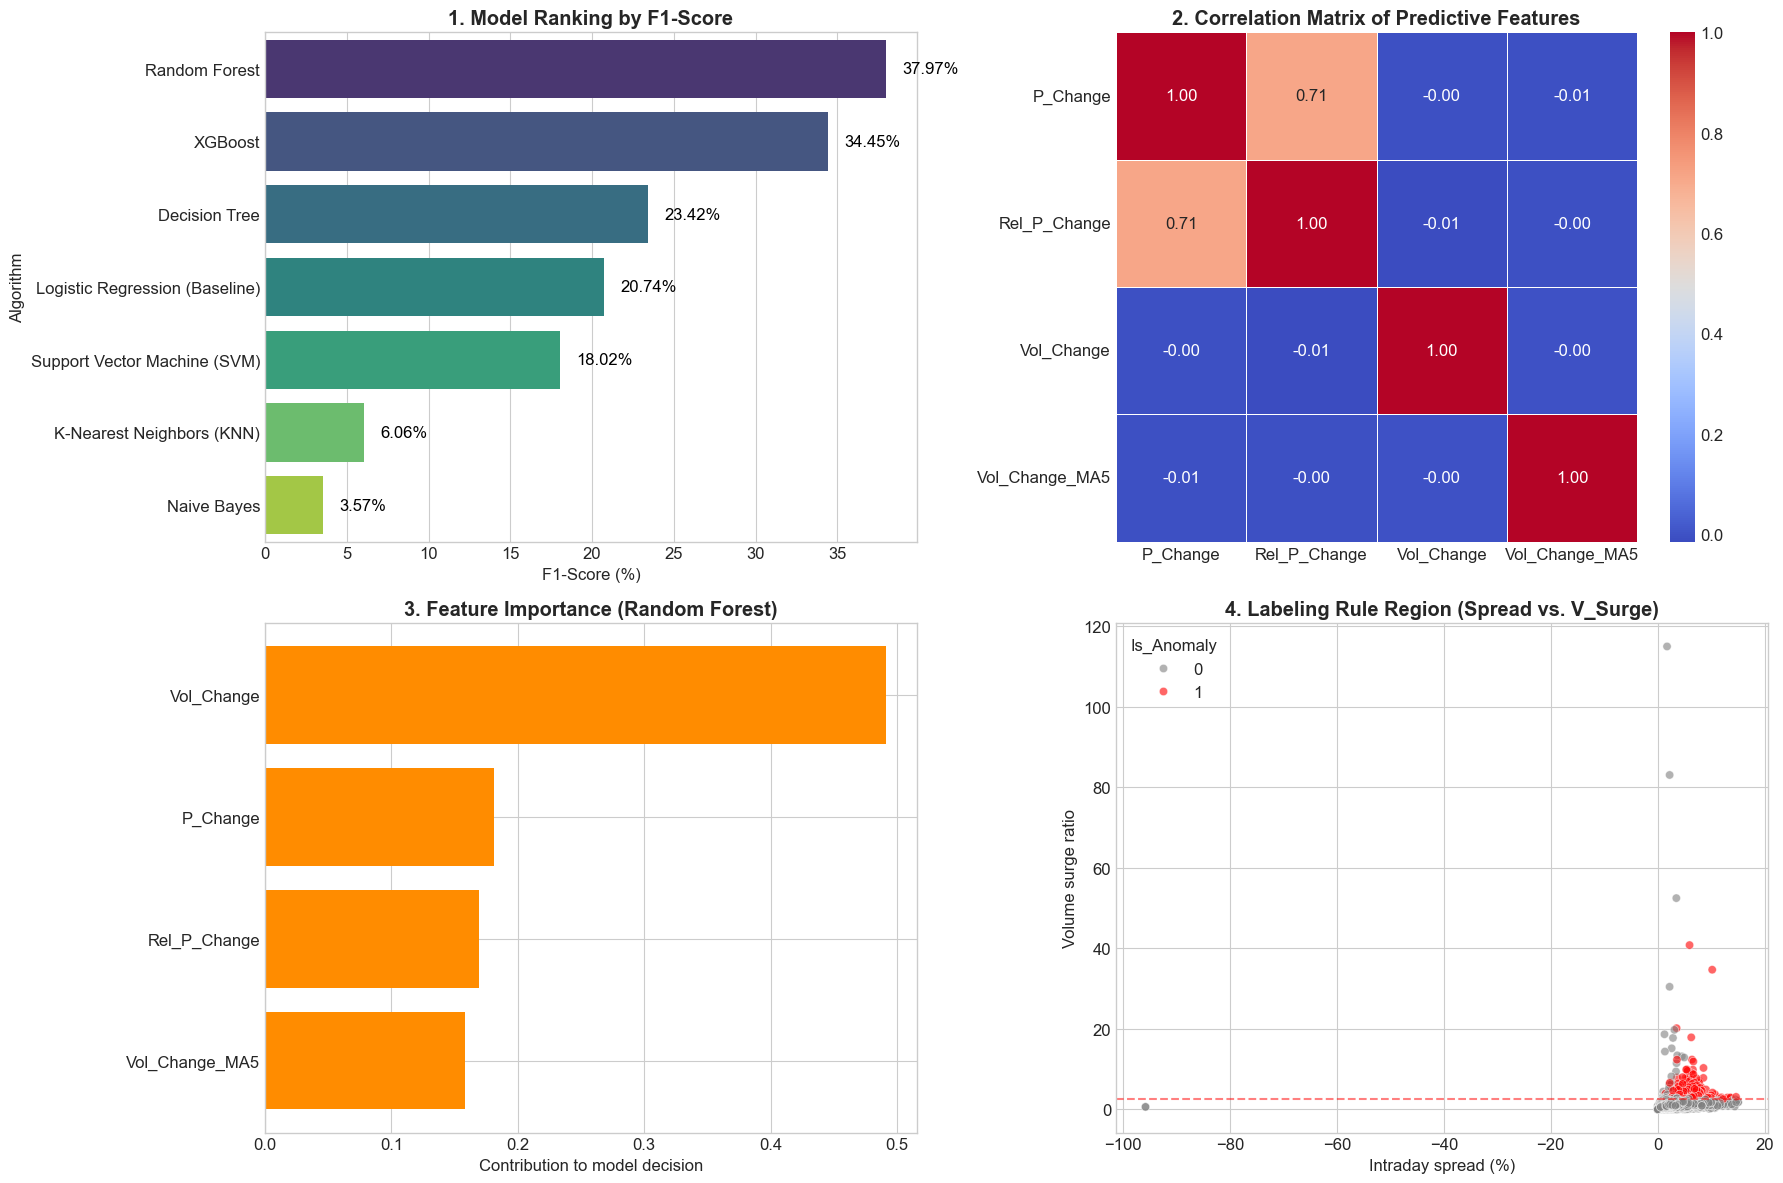

Saved: Final_Dashboard_EDA.png


In [3]:
"""
BLOCK 4 - EDA DASHBOARD
"""

import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.size'] = 12
fig = plt.figure(figsize=(18, 12))

plt.subplot(2, 2, 1)
sns.barplot(x='F1-Score (%)', y='Model', data=df_summary, palette='viridis')
plt.title('1. Model Ranking by F1-Score', fontweight='bold')
plt.xlabel('F1-Score (%)'); plt.ylabel('Algorithm')
for i, v in enumerate(df_summary['F1-Score (%)']):
    plt.text(v + 1, i, f"{v}%", color='black', va='center')

plt.subplot(2, 2, 2)
sns.heatmap(df_clean[FEATURE_COLS].corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('2. Correlation Matrix of Predictive Features', fontweight='bold')

plt.subplot(2, 2, 3)
importances = fitted_models['Random Forest'].feature_importances_
feature_labels = ['P_Change', 'Rel_P_Change', 'Vol_Change', 'Vol_Change_MA5']
order = np.argsort(importances)
plt.barh(range(len(order)), importances[order], color='darkorange')
plt.yticks(range(len(order)), [feature_labels[i] for i in order])
plt.title('3. Feature Importance (Random Forest)', fontweight='bold')
plt.xlabel('Contribution to model decision')

plt.subplot(2, 2, 4)
sns.scatterplot(data=df_clean, x='Spread', y='V_Surge', hue='Is_Anomaly',
                 palette={0: 'gray', 1: 'red'}, alpha=0.6)
plt.title('4. Labeling Rule Region (Spread vs. V_Surge)', fontweight='bold')
plt.xlabel('Intraday spread (%)'); plt.ylabel('Volume surge ratio')
plt.axhline(y=2.5, color='r', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('Final_Dashboard_EDA.png', dpi=300)
plt.show()
print("Saved: Final_Dashboard_EDA.png")


[BLOCK 5] Tuning XGBoost hyperparameters (SMOTE inside pipeline, TimeSeriesSplit CV)...
Best parameters: {'clf__learning_rate': 0.1, 'clf__max_depth': 7, 'clf__n_estimators': 200}

Optimal threshold (F1-maximizing): 0.932
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      3130
           1       0.47      0.40      0.43        58

    accuracy                           0.98      3188
   macro avg       0.73      0.69      0.71      3188
weighted avg       0.98      0.98      0.98      3188

F1 @ optimal threshold = 0.4299


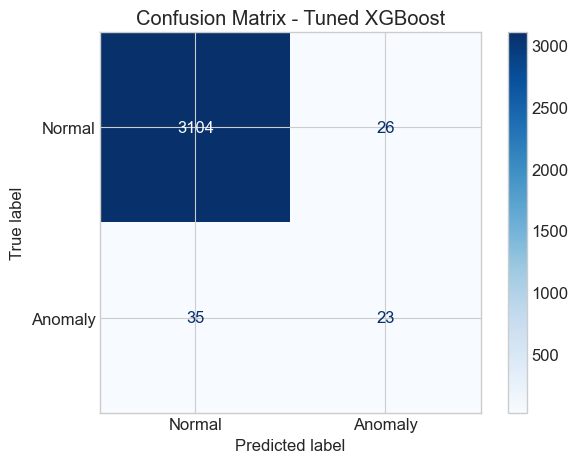


Computing SHAP values...


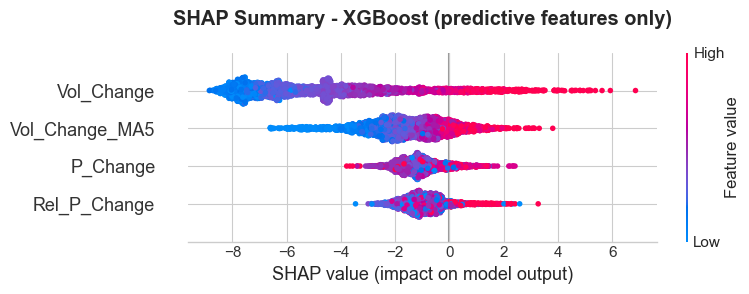


Cross-checking against Isolation Forest (unsupervised, includes Spread & V_Surge)...
Sessions flagged by both methods: 158 (rule-based total: 363, Isolation Forest total: 319)


In [4]:
"""
BLOCK 5 - HYPERPARAMETER TUNING, THRESHOLD SELECTION, EXPLAINABILITY
SMOTE is placed inside the Pipeline so oversampling happens only within each
training fold; TimeSeriesSplit is used instead of a shuffled K-Fold because
observations are chronologically dependent.
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import xgboost as xgb
import warnings
warnings.filterwarnings('ignore')

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.ensemble import IsolationForest
import shap
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                              precision_recall_curve, f1_score)

pipe = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('clf', xgb.XGBClassifier(random_state=42, eval_metric='logloss'))
])
param_grid = {
    'clf__n_estimators': [100, 200],
    'clf__max_depth': [3, 5, 7],
    'clf__learning_rate': [0.01, 0.05, 0.1]
}
cv = TimeSeriesSplit(n_splits=3)

print("[BLOCK 5] Tuning XGBoost hyperparameters (SMOTE inside pipeline, TimeSeriesSplit CV)...")
grid_search = GridSearchCV(pipe, param_grid, scoring='f1', cv=cv, n_jobs=-1)
grid_search.fit(X_train_scaled, y_train)
best_pipe = grid_search.best_estimator_
best_xgb = best_pipe.named_steps['clf']
print(f"Best parameters: {grid_search.best_params_}")

# --- Decision threshold selection (maximize F1 on the PR curve) --------------
y_prob_test = best_pipe.predict_proba(X_test_scaled)[:, 1]
prec_arr, rec_arr, thresh_arr = precision_recall_curve(y_test, y_prob_test)
f1_arr = 2 * prec_arr[:-1] * rec_arr[:-1] / (prec_arr[:-1] + rec_arr[:-1] + 1e-9)
best_thresh = thresh_arr[np.argmax(f1_arr)]
y_pred_tuned = (y_prob_test >= best_thresh).astype(int)

print(f"\nOptimal threshold (F1-maximizing): {best_thresh:.3f}")
print(classification_report(y_test, y_pred_tuned))
print(f"F1 @ optimal threshold = {f1_score(y_test, y_pred_tuned):.4f}")

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_tuned),
                        display_labels=['Normal', 'Anomaly']).plot(cmap='Blues')
plt.title('Confusion Matrix - Tuned XGBoost')
plt.tight_layout()
plt.savefig('Confusion_Matrix_Tuned.png', dpi=300)
plt.show()

# --- SHAP explainability -------------------------------------------------------
print("\nComputing SHAP values...")
explainer = shap.TreeExplainer(best_xgb)
X_test_df = pd.DataFrame(X_test_scaled, columns=FEATURE_COLS)
shap_values = explainer.shap_values(X_test_df)

plt.figure(figsize=(10, 6))
plt.title("SHAP Summary - XGBoost (predictive features only)", fontweight='bold', pad=20)
shap.summary_plot(shap_values, X_test_df, plot_type="dot", show=False)
plt.tight_layout()
plt.savefig('SHAP_Explainable_AI.png', dpi=300)
plt.show()

# --- Cross-check: unsupervised Isolation Forest on the full feature set -------
print("\nCross-checking against Isolation Forest (unsupervised, includes Spread & V_Surge)...")
iso_features = FEATURE_COLS + ['Spread', 'V_Surge']
iso = IsolationForest(n_estimators=200, contamination=0.02, random_state=42)
df_clean['Iso_Anomaly'] = np.where(iso.fit_predict(df_clean[iso_features]) == -1, 1, 0)
overlap = ((df_clean['Iso_Anomaly'] == 1) & (df_clean['Is_Anomaly'] == 1)).sum()
print(f"Sessions flagged by both methods: {overlap} "
      f"(rule-based total: {df_clean['Is_Anomaly'].sum()}, "
      f"Isolation Forest total: {df_clean['Iso_Anomaly'].sum()})")


[6.1] Walk-forward validation by quarter...
Current (excluded) quarter: 2026Q3 | Using 22 completed quarters.
Sessions per quarter (sanity check):
quarter
2021Q1    353
2021Q2    617
2021Q3    282
2021Q4    576
2022Q1    588
2022Q2    644
2022Q3    742
2022Q4    910
2023Q1    686
2023Q2    630
2023Q3    782
2023Q4    910
2024Q1    546
2024Q2    673
2024Q3    915
2024Q4    990
2025Q1    755
2025Q2    745
2025Q3    855
2025Q4    990
2026Q1    705
2026Q2    825
Freq: Q-DEC
Quarter  Train sessions  Test sessions  F1 (%)  PR-AUC (%)
 2022Q1            1828            588   40.00       46.58
 2022Q2            2416            644   28.57       14.61
 2022Q3            3060            742   38.10       63.82
 2022Q4            3802            910   25.00       32.37
 2023Q1            4712            686   27.91       69.16
 2023Q2            5398            630   33.33       46.22
 2023Q3            6028            782   32.84       32.15
 2023Q4            6810            910   18.52       

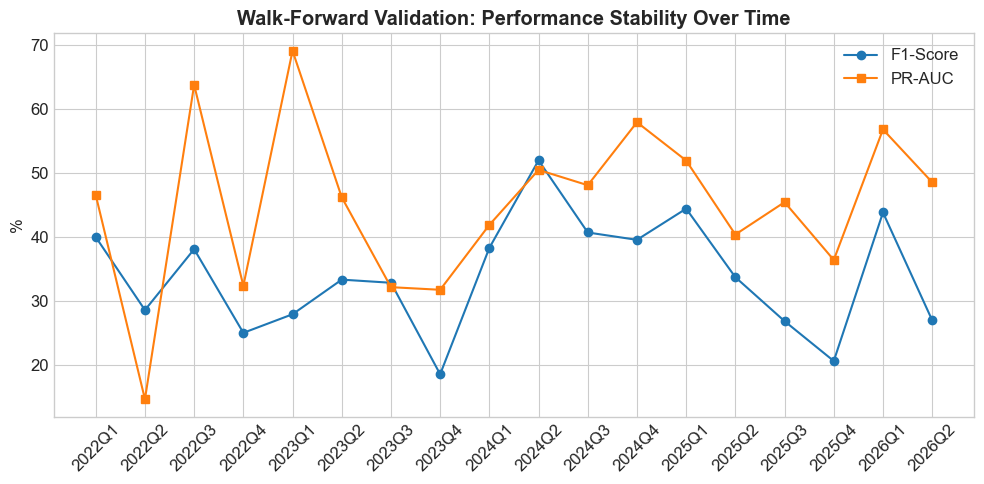


[6.2] Ablation study - contribution of Rel_P_Change...
             Feature set  F1 (%)  PR-AUC (%)
    Without Rel_P_Change   28.57       43.72
With Rel_P_Change (full)   32.28       45.36

[6.3] Top-5 highest-confidence flagged sessions (tuned XGBoost)...
Bank       date  P_Change  Rel_P_Change   Spread  V_Surge  Prob_Anomaly
 VIB 2026-03-09 -6.287425      0.086516 2.250804 6.570269      0.998437
 BID 2026-04-23  3.354040      3.107057 6.956522 3.415454      0.996874
 LPB 2025-12-23 -5.000008     -4.760575 7.272727 7.684080      0.996519
 LPB 2026-06-26 -5.357143     -5.648553 7.456979 2.567460      0.996154
 LPB 2025-08-13  6.284909      5.091691 7.334274 2.111850      0.995651
Saved: Top5_Flagged_Sessions.xlsx - cross-check these dates against news/disclosures for the report.


In [5]:
"""
BLOCK 6 - ROBUSTNESS CHECKS: WALK-FORWARD VALIDATION, ABLATION STUDY, CASE STUDY
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, average_precision_score
import warnings
warnings.filterwarnings('ignore')

df_clean['date'] = pd.to_datetime(df_clean['date'])
df_clean['quarter'] = df_clean['date'].dt.to_period('Q')

# -------------------------------------------------------------------------
# 6.1 Walk-forward validation: retrain on all data up to quarter t-1,
# evaluate on quarter t. Checks whether performance is stable over time
# rather than a one-off result from a single train/test split.
# -------------------------------------------------------------------------
print("[6.1] Walk-forward validation by quarter...")
# A fixed row-count cutoff is unreliable here: the number of listed banks
# (and thus rows per quarter) changed over time as some tickers IPO'd later,
# so "a full quarter" is not a constant row count across the sample.
# The only quarter that is structurally guaranteed to be incomplete is the
# current, still-open calendar quarter - exclude it explicitly by date.
current_quarter = pd.Timestamp.today().to_period('Q')
all_quarters = df_clean['quarter'].unique()
complete_quarters = [q for q in all_quarters if q < current_quarter]
df_wf_source = df_clean[df_clean['quarter'].isin(complete_quarters)].copy()
quarters = sorted(df_wf_source['quarter'].unique())
print(f"Current (excluded) quarter: {current_quarter} | Using {len(quarters)} completed quarters.")

quarter_counts = df_wf_source['quarter'].value_counts().sort_index()
print("Sessions per quarter (sanity check):")
print(quarter_counts.to_string())
wf_results = []
for i in range(4, len(quarters)):  # need a few quarters of history before the first test quarter
    train_q = quarters[:i]
    test_q = quarters[i]
    train_wf = df_wf_source[df_wf_source['quarter'].isin(train_q)]
    test_wf = df_wf_source[df_wf_source['quarter'] == test_q]

    if train_wf['Is_Anomaly'].sum() < 5 or test_wf['Is_Anomaly'].sum() < 1:
        continue  # skip quarters with too few positive cases to evaluate meaningfully

    sc = StandardScaler().fit(train_wf[FEATURE_COLS])
    Xtr, Xte = sc.transform(train_wf[FEATURE_COLS]), sc.transform(test_wf[FEATURE_COLS])
    ytr, yte = train_wf['Is_Anomaly'], test_wf['Is_Anomaly']

    spw = (len(ytr) - ytr.sum()) / max(ytr.sum(), 1)
    m = xgb.XGBClassifier(random_state=42, n_estimators=150, max_depth=5,
                           learning_rate=0.05, eval_metric='logloss', scale_pos_weight=spw)
    m.fit(Xtr, ytr)
    y_prob = m.predict_proba(Xte)[:, 1]
    y_pred = (y_prob >= 0.5).astype(int)
    wf_results.append({
        'Quarter': str(test_q),
        'Train sessions': len(train_wf),
        'Test sessions': len(test_wf),
        'F1 (%)': round(f1_score(yte, y_pred, zero_division=0) * 100, 2),
        'PR-AUC (%)': round(average_precision_score(yte, y_prob) * 100, 2),
    })

df_wf = pd.DataFrame(wf_results)
print(df_wf.to_string(index=False))
df_wf.to_excel('Walk_Forward_Validation.xlsx', index=False)

plt.figure(figsize=(10, 5))
plt.plot(df_wf['Quarter'], df_wf['F1 (%)'], marker='o', label='F1-Score')
plt.plot(df_wf['Quarter'], df_wf['PR-AUC (%)'], marker='s', label='PR-AUC')
plt.xticks(rotation=45)
plt.title('Walk-Forward Validation: Performance Stability Over Time', fontweight='bold')
plt.ylabel('%'); plt.legend(); plt.tight_layout()
plt.savefig('Walk_Forward_Validation.png', dpi=300)
plt.show()

# -------------------------------------------------------------------------
# 6.2 Ablation study: does Rel_P_Change add value over the original 3 features?
# -------------------------------------------------------------------------
print("\n[6.2] Ablation study - contribution of Rel_P_Change...")
feature_sets = {
    'Without Rel_P_Change': ['P_Change', 'Vol_Change', 'Vol_Change_MA5'],
    'With Rel_P_Change (full)': FEATURE_COLS,
}
ablation_results = []
for label, cols in feature_sets.items():
    sc = StandardScaler().fit(X_train[cols])
    Xtr, Xte = sc.transform(X_train[cols]), sc.transform(X_test[cols])
    spw = (len(y_train) - y_train.sum()) / max(y_train.sum(), 1)
    m = xgb.XGBClassifier(random_state=42, n_estimators=200, max_depth=5,
                           learning_rate=0.05, eval_metric='logloss', scale_pos_weight=spw)
    m.fit(Xtr, y_train)
    y_prob = m.predict_proba(Xte)[:, 1]
    y_pred = (y_prob >= 0.5).astype(int)
    ablation_results.append({
        'Feature set': label,
        'F1 (%)': round(f1_score(y_test, y_pred, zero_division=0) * 100, 2),
        'PR-AUC (%)': round(average_precision_score(y_test, y_prob) * 100, 2),
    })
print(pd.DataFrame(ablation_results).to_string(index=False))

# -------------------------------------------------------------------------
# 6.3 Case study: top-5 highest-probability anomalies flagged by the tuned model
# -------------------------------------------------------------------------
print("\n[6.3] Top-5 highest-confidence flagged sessions (tuned XGBoost)...")
test_df = test_df.reset_index(drop=True)
test_df['Prob_Anomaly'] = y_prob_test
top5 = test_df.sort_values('Prob_Anomaly', ascending=False).head(5)
print(top5[['Bank', 'date', 'P_Change', 'Rel_P_Change', 'Spread', 'V_Surge', 'Prob_Anomaly']].to_string(index=False))
top5.to_excel('Top5_Flagged_Sessions.xlsx', index=False)
print("Saved: Top5_Flagged_Sessions.xlsx - cross-check these dates against news/disclosures for the report.")
